### 1.Import librariries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMClassifier
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
import joblib
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_predict
from sklearn.model_selection import learning_curve
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from bayes_opt import BayesianOptimization
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve, f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve

In [2]:
sns.set_style("darkgrid")

### 2.Knowing the data

In [3]:
data = pd.read_csv("UCI_Heart_Disease_Dataset_Combined.csv")
data.head(5)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,HeartDisease
0,40,1,1,140,289,0,0,172,0,0.0,0
1,49,0,2,160,180,0,0,156,0,1.0,1
2,37,1,1,130,283,0,1,98,0,0.0,0
3,48,0,3,138,214,0,0,108,1,1.5,1
4,54,1,2,150,195,0,0,122,0,0.0,0


In [4]:
data.describe()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,HeartDisease
count,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000,2943.000000
mean,52.381923,0.748556,1.363575,138.698267,253.515121,0.225280,0.626911,144.040095,0.412504,1.570031,0.548420
std,13.037189,0.433917,1.142614,24.623198,112.724716,0.417838,0.713650,28.446327,0.492369,1.585102,0.497735
min,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000
25%,44.000000,0.000000,0.000000,120.500000,204.000000,0.000000,0.000000,124.000000,0.000000,0.100000,0.000000
50%,54.000000,1.000000,1.000000,134.000000,248.000000,0.000000,0.000000,145.000000,0.000000,1.200000,1.000000
75%,61.000000,1.000000,2.000000,150.000000,306.000000,0.000000,1.000000,165.000000,1.000000,2.400000,1.000000
max,80.000000,1.000000,3.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,1.000000


The first step is to separate the categorical features from the numerical features.

In [5]:
data.dtypes

Age                 int64
Sex                 int64
ChestPainType       int64
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG          int64
MaxHR               int64
ExerciseAngina      int64
Oldpeak           float64
HeartDisease        int64
dtype: object

In [6]:
data.nunique()

Age                61
Sex                 2
ChestPainType       4
RestingBP         106
Cholesterol       390
FastingBS           2
RestingECG          3
MaxHR             137
ExerciseAngina      2
Oldpeak            73
HeartDisease        2
dtype: int64

In [7]:
data["HeartDisease"].value_counts()

HeartDisease
1    1614
0    1329
Name: count, dtype: int64

In [8]:
columns_to_object = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "HeartDisease"]
for col in columns_to_object:
    data[col] = data[col].astype("category")

In [9]:
cat_col = data.select_dtypes(include="category").columns.to_list()
cat_col.remove("HeartDisease")
num_col = data.select_dtypes(exclude="category").columns.to_list()
print("columns that are categorical :", cat_col)
print("columns that are numerical :", num_col)

columns that are categorical : ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina']
columns that are numerical : ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


### 3.Dealing with nan values

In [10]:
data[data.isnull().any(axis=1)]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,HeartDisease


There are no null values in the dataset; however, we know that missing data can sometimes appear in the form of outliers.

### 4.Univariate analysis

#### 4.1 Target analysis

<Axes: xlabel='HeartDisease', ylabel='count'>

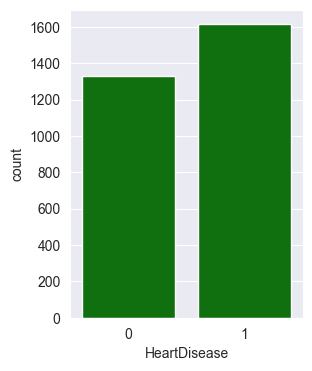

In [11]:
plt.figure(figsize=(3,4))
sns.countplot(data=data, x="HeartDisease", color="green")

#### 4.2 Categorical analysis

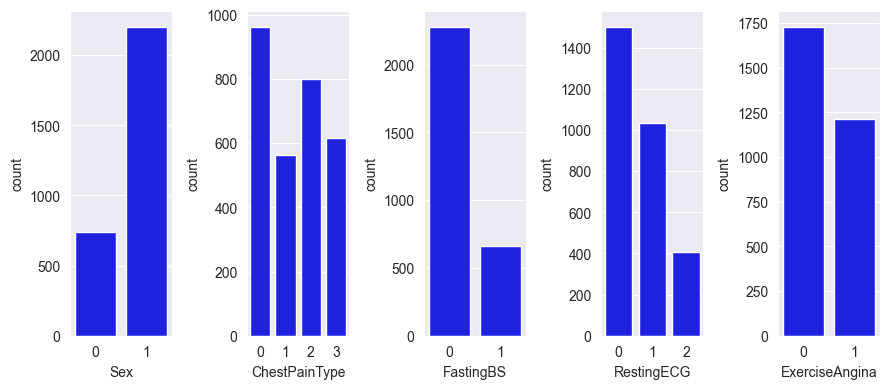

In [12]:
plt.figure(figsize=(9, 4))
for i, col in enumerate(cat_col,1):
    plt.subplot(1, len(cat_col), i)
    sns.countplot(data=data, x=col, color='b')
plt.tight_layout()

#### 4.3  Numerical analysis

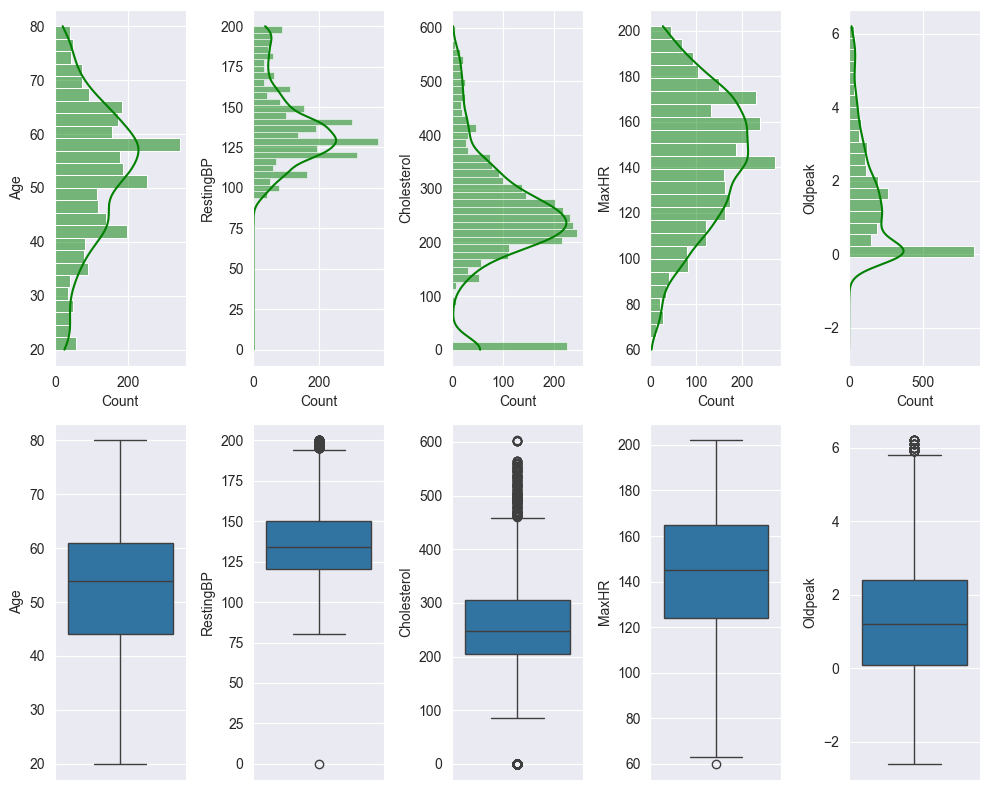

In [13]:
plt.figure(figsize=(10,8))
for i, col in enumerate(num_col,1):
    plt.subplot(2,len(num_col), i)
    sns.histplot(data=data, y=col, kde=True, color='g')
    plt.subplot(2, len(num_col), i + len(num_col))
    sns.boxplot(data=data, y=col)
plt.tight_layout()

In [14]:
skew_kurtosis = pd.DataFrame({
    "skew" : data[num_col].skew(),
    "kurtosis" : data[num_col].kurtosis()
    })
skew_kurtosis.T

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
skew,-0.369582,0.678258,-0.015260,-0.271919,0.988657
kurtosis,-0.242169,0.325689,1.042676,-0.478438,0.265135


Oldpeak is relatively skewed to right

In [15]:
data.loc[data["Cholesterol"] == 0, "Cholesterol"] = data.loc[data["Cholesterol"] != 0, "Cholesterol"].median()
data.loc[data["RestingBP"] == 0, "RestingBP"] = data.loc[data["RestingBP"] != 0, "RestingBP"].median()

### 5. Bivariate analysis

#### 5.1. Categorical analysis

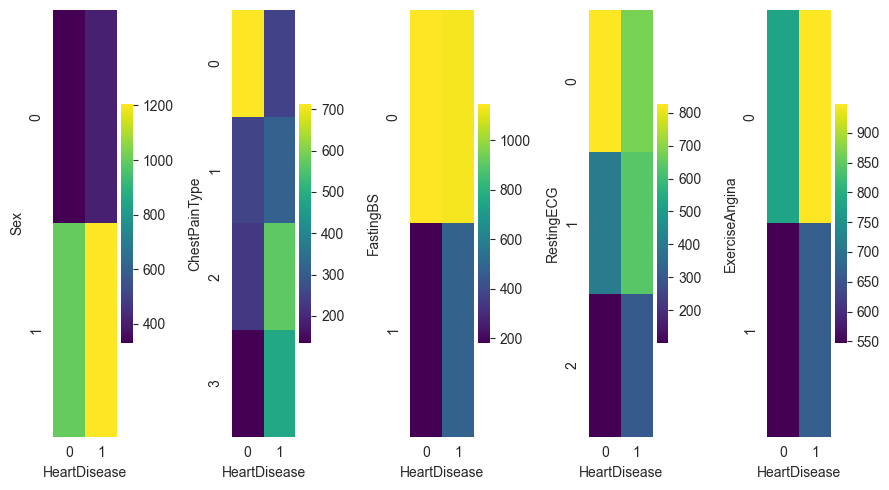

In [16]:
plt.figure(figsize=(9,5))
for i, col in enumerate(cat_col,1):
    plt.subplot(1,len(cat_col), i)
    sns.heatmap(pd.crosstab(data[col], data["HeartDisease"]), cmap="viridis", fmt='d')
plt.tight_layout()

#### 5.2. Numerical analysis

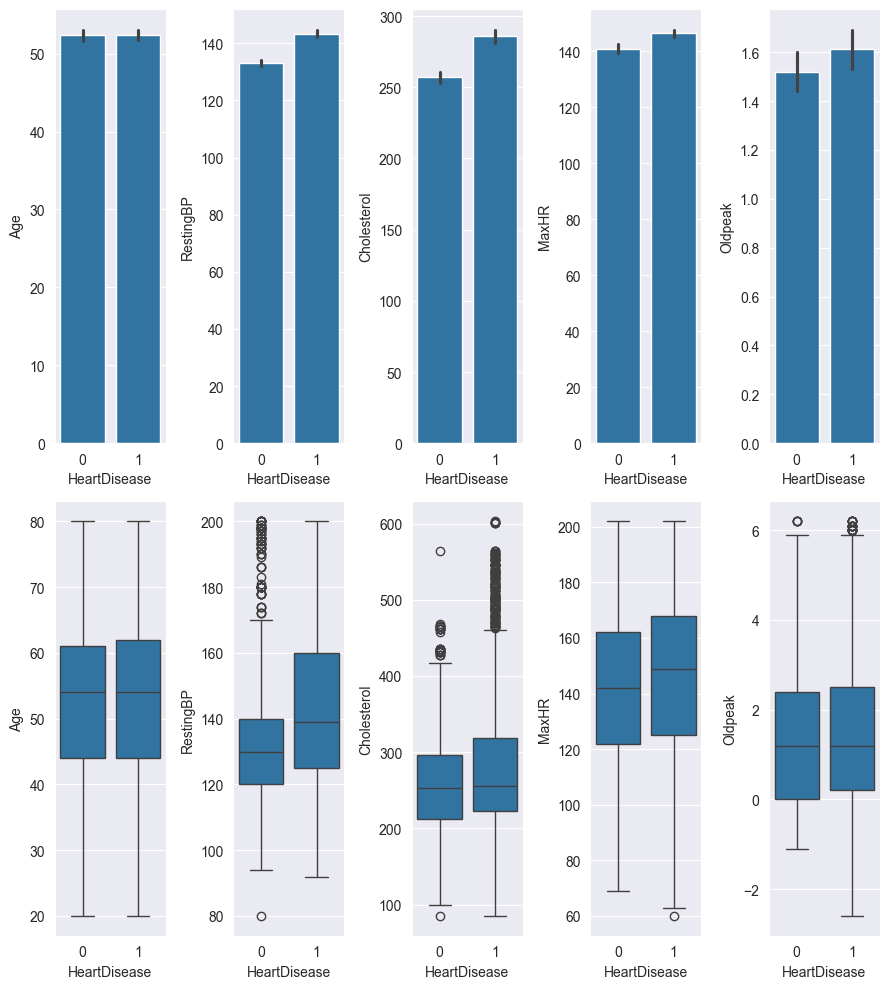

In [17]:
plt.figure(figsize=(9,10))
for i, col in enumerate(num_col,1):
    plt.subplot(2, len(num_col), i)
    sns.barplot(data=data, x="HeartDisease", y=col)
    plt.subplot(2, len(num_col), i+len(num_col))
    sns.boxplot(data=data, x="HeartDisease", y=col)
plt.tight_layout()

### 6. Multivariate analysis

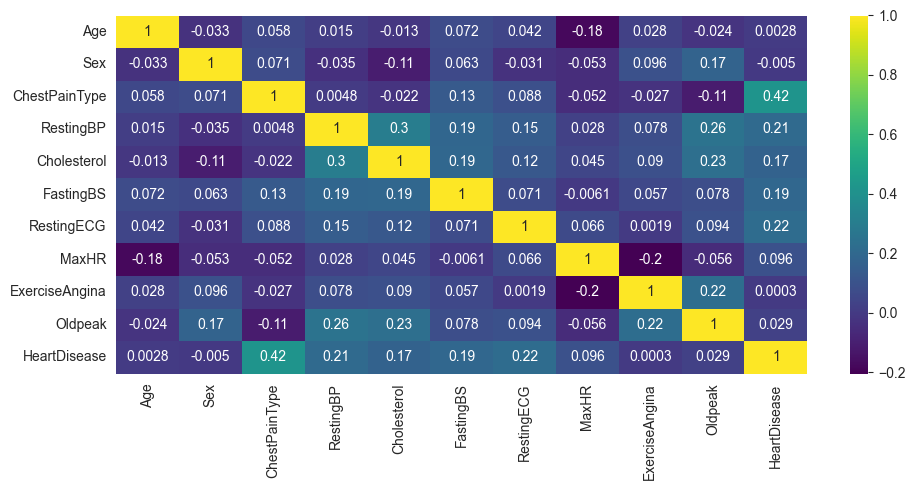

In [18]:
correlation = data.corr()
plt.figure(figsize=(10,5))
sns.heatmap(correlation, cmap="viridis", annot=True)
plt.tight_layout()

As shown, there is no strong correlation between the variables and the target, except for `ChestPainType`.


### 7. Outlire treatment

In [19]:
pt = PowerTransformer(method="yeo-johnson",standardize=False)
transformed = pt.fit_transform(data[["Oldpeak"]])
data["Oldpeak"] = transformed.flatten()
data["Oldpeak"] = transformed[:,0]
data["Cholesterol"] = np.sqrt(data["Cholesterol"])

The columns `Oldpeak` and `Cholesterol` require transformation due to their high skewness.

In [20]:
columns_to_watch = ["RestingBP", "Cholesterol", "Oldpeak"]

In [21]:
outlier_list = []

for col in columns_to_watch:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR
    
    outlier_list.append(
        data[(data[col] < lower) | (data[col] > upper)]
    )

totally_outliers = pd.concat(outlier_list, ignore_index=True).drop_duplicates()
totally_outliers

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,HeartDisease
0,46,1,3,100,15.968719,1,1,133,0,-5.360109,1
1,56,1,2,125,15.968719,1,0,98,0,-3.653082,1


We also clip the values of these columns when they are far from the normal range.

In [22]:
down_clip = data["Oldpeak"].quantile(0.01)
up_clip = data["Oldpeak"].quantile(0.99)
data["Oldpeak"] = data["Oldpeak"].clip(lower=down_clip, upper=up_clip)

### 8.Splitting Data

We then split the data into training and test sets. We use the `stratify` parameter to ensure that the target classes are distributed proportionally across both sets.

In [23]:
x = data.drop("HeartDisease", axis=1)
y = data["HeartDisease"]

In [24]:
x_train, x_test, y_train, y_test  = train_test_split(x, y , test_size=0.20,stratify=y, random_state=42)

### 9.Modeling

#### 9.1.LightGBM

The first algorithm we use is LightGBM. It is known for its efficient memory usage and strong performance on tabular datasets.

LightGBM can handle categorical features natively, so one‑hot encoding is not required when the features are specified as categorical.

We use the `scale_pos_weight` parameter to address class imbalance by increasing the importance of the positive class during training.


In [25]:
LGBM_model = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=10,
    num_leaves=15,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    reg_alpha=2.0,
    reg_lambda=2.0,
    n_jobs=-1,
    scale_pos_weight=1.10, 
    )
LGBM_model.fit(
    x_train,
    y_train,
    categorical_feature=cat_col
)
y_pred = LGBM_model.predict(x_test)

[LightGBM] [Info] Number of positive: 1291, number of negative: 1063
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001447 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 622
[LightGBM] [Info] Number of data points in the train set: 2354, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548428 -> initscore=0.194322
[LightGBM] [Info] Start training from score 0.194322
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

In [26]:
print(f"accuracy_score is : {accuracy_score(y_test, y_pred)}")
print(f"precision_score is : {precision_score(y_test, y_pred)}")
print(f"recall_score is : {recall_score(y_test, y_pred)}")
print(f"f1_score is : {f1_score(y_test, y_pred)}")

accuracy_score is : 0.831918505942275
precision_score is : 0.827485380116959
recall_score is : 0.8761609907120743
f1_score is : 0.8511278195488722


The scores show very good results and suggest that the model has been trained properly.

But is the model really performing well? We need to verify several aspects before reaching that conclusion.

In [27]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(LGBM_model, x, y, cv=cv, scoring="recall")
print(f"average score is : {scores.mean()}")

[LightGBM] [Info] Number of positive: 1452, number of negative: 1196
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000247 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 624
[LightGBM] [Info] Number of data points in the train set: 2648, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548338 -> initscore=0.193959
[LightGBM] [Info] Start training from score 0.193959
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

The result is close to what we observed earlier.  
But wait—we are not done yet.  
We need to examine the learning curve to check for signs of overfitting or underfitting.

[LightGBM] [Info] Number of positive: 96, number of negative: 168
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000188 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 195
[LightGBM] [Info] Number of data points in the train set: 264, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.363636 -> initscore=-0.559616
[LightGBM] [Info] Start training from score -0.559616
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


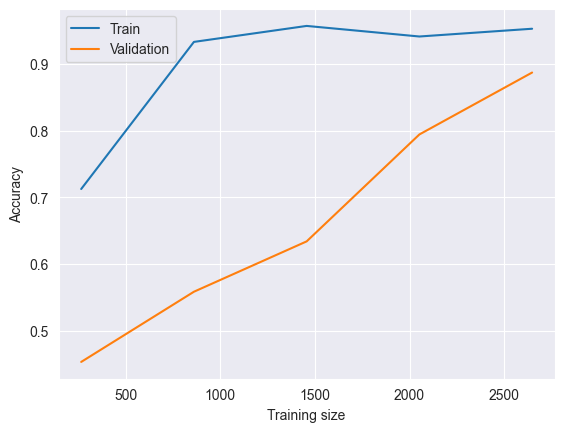

train_scores : [[0.69791667 0.70652174 0.72164948 0.71134021 0.71134021 0.7244898
  0.73737374 0.68817204 0.71717172 0.70833333]
 [0.93404255 0.93644068 0.93360996 0.93234672 0.92887029 0.93684211
  0.93775934 0.92811839 0.93305439 0.93110647]
 [0.95609756 0.95848596 0.96493349 0.95710784 0.95747266 0.95868773
  0.95625759 0.95736906 0.9528416  0.9527845 ]
 [0.94535993 0.93913043 0.94137931 0.9461338  0.93402778 0.9358196
  0.94974003 0.94199134 0.94285714 0.93685121]
 [0.95385675 0.95592287 0.95523416 0.95801789 0.94907089 0.95526497
  0.94356504 0.95801789 0.95110193 0.94972452]]
val_scores : [[0.41975309 0.48765432 0.46296296 0.43478261 0.50931677 0.39751553
  0.47204969 0.49689441 0.39751553 0.45061728]
 [0.48765432 0.60493827 0.59259259 0.57763975 0.60869565 0.53416149
  0.57142857 0.58385093 0.49689441 0.52469136]
 [0.62962963 0.66666667 0.64814815 0.64596273 0.65838509 0.56521739
  0.66459627 0.67701863 0.58385093 0.59876543]
 [0.83333333 0.78395062 0.75925926 0.80745342 0.81987

In [28]:
train_sizes, train_scores, val_scores = learning_curve(
    LGBM_model, x, y, cv=cv, scoring='recall',
    train_sizes=np.linspace(0.1, 1.0, 5)
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), label='Validation')
plt.xlabel("Training size")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print(f"train_scores : {train_scores}")
print(f"val_scores : {val_scores}")

Well, this is not ideal. As we can see, there is a large gap between the training accuracy and the validation accuracy. 
Additionally, the validation score is quite low when the model is trained on a small amount of data. Although the performance improves as more data is used, this suggests that the issue may not be solely due to insufficient data.

To gain a clearer understanding of the model’s behavior, we use cross_val_score.  
Our goal is to estimate the model’s bias, the overfitting gap, and the amount of variance in its performance.

In [29]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

LGBM_model.fit(x_train, y_train)
train_recall = recall_score(y_train, LGBM_model.predict(x_train))

val_recalls = cross_val_score(
    LGBM_model, x_train, y_train, cv=cv, scoring="recall"
)
val_mean = val_recalls.mean()
val_std  = val_recalls.std()


bias_estimate = 1 - val_mean
variance_estimate = val_std
overfit_gap = train_recall - val_mean

print("TRAIN recall:", train_recall)
print("VAL recall mean:", val_mean)
print("VAL recall std:", val_std)

print("\nBias estimate:", bias_estimate)
print("Variance estimate:", variance_estimate)
print("Overfitting gap:", overfit_gap)


[LightGBM] [Info] Number of positive: 1291, number of negative: 1063
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000242 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 622
[LightGBM] [Info] Number of data points in the train set: 2354, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548428 -> initscore=0.194322
[LightGBM] [Info] Start training from score 0.194322
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

The bias is moderate, the variance is within an acceptable range, and the overfitting gap is also moderate. Overall, the model appears to have achieved a well-balanced bias–variance tradeoff. Therefore, no further modifications will be made, and we will proceed to the next model.

#### 9.2 Random forrest

The next model we evaluate is Random forest. Unlike LightGBM, Random forest does not support native 
categorical features, meaning that all categorical variables must be encoded before 
training. For this purpose, we apply One‑Hot Encoding, which converts each categorical 
feature into a set of binary indicator variables. This ensures that Random forest can properly 
interpret the categorical information during training.

In [30]:
cat_encoder = OneHotEncoder()
cat_encoded = cat_encoder.fit_transform(data[cat_col]).toarray()
encoded_df = pd.DataFrame(cat_encoded, columns=cat_encoder.get_feature_names_out(cat_col), index=data.index)
data = pd.concat([data.drop(columns=cat_col), encoded_df], axis=1)

In [31]:
x = data.drop("HeartDisease", axis=1)
y = data["HeartDisease"]

We now split the data again to account for the preprocessing changes we applied.

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20,stratify=y, random_state=42)

The remainder of the workflow is identical to the LightGBM procedure, so no additional 
explanations are necessary at this stage.


In [33]:
rf_model = RandomForestClassifier(
    n_estimators=2500,
    max_depth=14,
    min_samples_split=3,
    min_samples_leaf=3,     
    max_features= "sqrt",       
    class_weight="balanced",
    criterion="gini",
    ccp_alpha=0.0001,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(x_train, y_train)
y_pred = rf_model.predict(x_test)

In [34]:
print(f"accuracy_score is : {accuracy_score(y_test, y_pred)}")
print(f"precision_score is : {precision_score(y_test, y_pred)}")
print(f"recall_score is : {recall_score(y_test, y_pred)}")
print(f"f1_score is : {f1_score(y_test, y_pred)}")

accuracy_score is : 0.8811544991511036
precision_score is : 0.8868501529051988
recall_score is : 0.8978328173374613
f1_score is : 0.8923076923076924


In [35]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(rf_model, x, y, cv=cv, scoring='recall')
print(f"average score is : {scores.mean()}")

average score is : 0.9039567517828389


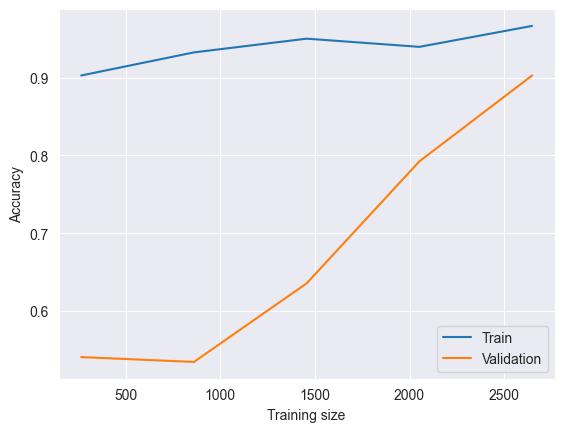

train_scores : [[0.90625    0.92391304 0.88659794 0.88659794 0.90721649 0.89795918
  0.88888889 0.91397849 0.88888889 0.92708333]
 [0.92765957 0.93644068 0.93153527 0.93868922 0.93933054 0.93473684
  0.92323651 0.92600423 0.92887029 0.93736952]
 [0.94634146 0.95482295 0.94679565 0.95343137 0.95139733 0.95382746
  0.94653706 0.95127893 0.94558646 0.9503632 ]
 [0.94622723 0.93913043 0.94051724 0.94178975 0.93663194 0.94015611
  0.94194107 0.93419913 0.93852814 0.93598616]
 [0.96487603 0.96694215 0.96625344 0.96765313 0.96971783 0.96558844
  0.96558844 0.96558844 0.96831956 0.96349862]]
val_scores : [[0.53703704 0.58641975 0.48148148 0.58385093 0.60248447 0.46583851
  0.52795031 0.55900621 0.50931677 0.55555556]
 [0.48765432 0.59876543 0.53703704 0.53416149 0.62111801 0.45962733
  0.55279503 0.56521739 0.49068323 0.5       ]
 [0.64814815 0.64814815 0.67901235 0.64596273 0.66459627 0.55900621
  0.65838509 0.68322981 0.57763975 0.59259259]
 [0.82098765 0.81481481 0.81481481 0.79503106 0.819

In [37]:
train_sizes, train_scores, val_scores = learning_curve(
    rf_model, x, y, cv=cv, scoring='recall',
    train_sizes=np.linspace(0.1, 1.0, 5)
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), label='Validation')
plt.xlabel("Training size")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print(f"train_scores : {train_scores}")
print(f"val_scores : {val_scores}")

In [38]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rf_model.fit(x_train, y_train)
train_recall = recall_score(y_train, rf_model.predict(x_train))

val_recalls = cross_val_score(
    rf_model, x_train, y_train, cv=cv, scoring="recall"
)
val_mean = val_recalls.mean()
val_std  = val_recalls.std()

bias_estimate = 1 - val_mean
variance_estimate = val_std
overfit_gap = train_recall - val_mean

print("TRAIN recall:", train_recall)
print("VAL recall mean:", val_mean)
print("VAL recall std:", val_std)

print("\nBias estimate:", bias_estimate)
print("Variance estimate:", variance_estimate)
print("Overfitting gap:", overfit_gap)

TRAIN recall: 0.9666924864446166
VAL recall mean: 0.8660107334525939
VAL recall std: 0.023929584990645413

Bias estimate: 0.13398926654740606
Variance estimate: 0.023929584990645413
Overfitting gap: 0.10068175299202264


The results are similar to those observed earlier with LGBM. As in that case, the model has achieved a suitable balance in the bias–variance tradeoff. Therefore, we will not make any further modifications and will proceed to our final model, which is commonly used in many Kaggle competitions: XGBoost.

#### 9.3.XGBoost

The final model evaluated in this project is XGBoost. This algorithm is widely used in machine learning applications and has achieved strong performance in many data science competitions, including Kaggle. Due to its ability to handle complex nonlinear relationships and apply regularization techniques, XGBoost is considered a suitable candidate for this project.

In [39]:
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=8,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    reg_alpha=1.2,
    reg_lambda=1.4,
    n_jobs=-1,
    scale_pos_weight=1.10,
    eval_metric="logloss"
    )
xgb_model.fit(
    x_train,
    y_train,
    verbose=True
)
y_pred = xgb_model.predict(x_test)

In [40]:
print(f"accuracy_score is : {accuracy_score(y_test, y_pred)}")
print(f"precision_score is : {precision_score(y_test, y_pred)}")
print(f"recall_score is : {recall_score(y_test, y_pred)}")
print(f"f1_score is : {f1_score(y_test, y_pred)}")

accuracy_score is : 0.8590831918505942
precision_score is : 0.8550295857988166
recall_score is : 0.8947368421052632
f1_score is : 0.8744326777609682


In [41]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(xgb_model, x_train, y_train, cv=cv, scoring="recall")
print(f"average score is : {scores.mean()}")

average score is : 0.8830292188431723


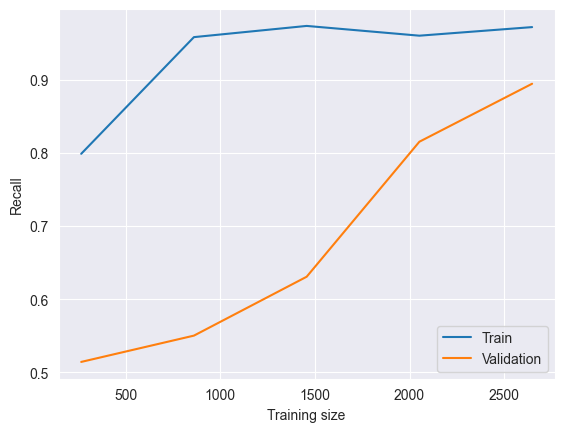

train_scores : [[0.79166667 0.80434783 0.84536082 0.81443299 0.77319588 0.7755102
  0.78787879 0.78494624 0.77777778 0.83333333]
 [0.95106383 0.95762712 0.95228216 0.95983087 0.96443515 0.96
  0.9626556  0.96194503 0.95606695 0.95824635]
 [0.97317073 0.97191697 0.97823458 0.9754902  0.97569866 0.96962333
  0.97691373 0.97076736 0.97339782 0.97215496]
 [0.95836947 0.95217391 0.96206897 0.96177237 0.9609375  0.96183868
  0.96360485 0.96017316 0.96017316 0.96280277]
 [0.97038567 0.97107438 0.97520661 0.97660014 0.97384721 0.97384721
  0.96558844 0.97178252 0.97176309 0.97107438]]
val_scores : [[0.48765432 0.51234568 0.51234568 0.54037267 0.60869565 0.42236025
  0.52795031 0.54658385 0.43478261 0.54938272]
 [0.48765432 0.59259259 0.57407407 0.52173913 0.60248447 0.53416149
  0.59627329 0.58385093 0.49689441 0.51234568]
 [0.63580247 0.65432099 0.63580247 0.64596273 0.67080745 0.56521739
  0.64596273 0.68322981 0.57763975 0.59259259]
 [0.82716049 0.80246914 0.82098765 0.8447205  0.82608696 0

In [42]:
train_sizes, train_scores, val_scores = learning_curve(
    xgb_model, x, y, cv=cv, scoring='recall',
    train_sizes=np.linspace(0.1, 1.0, 5)
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), label='Validation')
plt.xlabel("Training size")
plt.ylabel("Recall")
plt.legend()
plt.show()

print(f"train_scores : {train_scores}")
print(f"val_scores : {val_scores}")

In [43]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

xgb_model.fit(x_train, y_train)
train_recall = recall_score(y_train, xgb_model.predict(x_train))

val_recalls = cross_val_score(
    xgb_model, x_train, y_train, cv=cv, scoring="recall"
)
val_mean = val_recalls.mean()
val_std  = val_recalls.std()

bias_estimate = 1 - val_mean
variance_estimate = val_std
overfit_gap = train_recall - val_mean

print("TRAIN recall:", train_recall)
print("VAL recall mean:", val_mean)
print("VAL recall std:", val_std)

print("\nBias estimate:", bias_estimate)
print("Variance estimate:", variance_estimate)
print("Overfitting gap:", overfit_gap)

TRAIN recall: 0.9705654531371031
VAL recall mean: 0.8830292188431723
VAL recall std: 0.034419596408885686

Bias estimate: 0.11697078115682769
Variance estimate: 0.034419596408885686
Overfitting gap: 0.08753623429393076


Overall, the XGBoost model remains the best option among the models we evaluated. It 
provides a more favorable balance between recall, precision, bias, variance, and 
generalization behavior. For this reason, we select XGBoost as our final model.

By default, classification models use a probability threshold of 0.50 to convert predicted
probabilities into class labels. However, in medical applications this default threshold 
is often not ideal. In such settings, it is usually more important to identify as many 
positive cases as possible (i.e., achieve high recall), while still maintaining a reasonable 
precision to avoid excessive false positives.

To find the most appropriate balance between recall and precision, we examine the 
precision–recall curve. This allows us to select a threshold that maximizes recall without 
causing an unacceptable drop in precision.

As the results show, we can achieve a substantially higher recall compared to the default 
0.50 threshold, and at the same time the precision remains at an acceptable level. 
Overall, this threshold adjustment leads to a much better performance for our medical 
use‑case.

In [44]:
y_proba = xgb_model.predict_proba(x_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
beta = 2
precision_adj = precisions[:-1]
recall_adj = recalls[:-1]
f2_scores = (1 + beta**2) * (precision_adj * recall_adj) / ((beta**2 * precision_adj) + recall_adj)
best_index = np.argmax(f2_scores)
best_threshold = thresholds[best_index]
best_precision = precision_adj[best_index]
best_recall = recall_adj[best_index]
best_f2 = f2_scores[best_index]
y_pred_opt = (y_proba >= best_threshold).astype(int)

print(f"accuracy_score is : {accuracy_score(y_test, y_pred_opt)}")
print(f"precision_score is : {precision_score(y_test, y_pred_opt)}")
print(f"recall_score is : {recall_score(y_test, y_pred_opt)}")
print(f"f1_score is : {f1_score(y_test, y_pred_opt)}")
print(f"f2_score is : {best_f2}")
print(confusion_matrix(y_test, y_pred_opt))

accuracy_score is : 0.8132427843803056
precision_score is : 0.762962962962963
recall_score is : 0.9566563467492261
f1_score is : 0.8489010989010989
f2_score is : 0.9104301708898056
[[170  96]
 [ 14 309]]


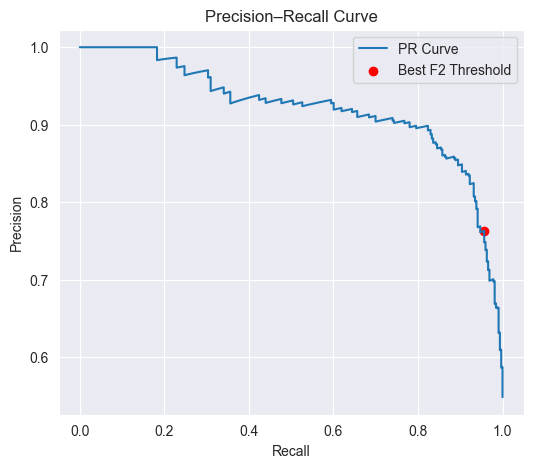

In [45]:
plt.figure(figsize=(6,5))
plt.plot(recalls, precisions, label="PR Curve")
plt.scatter(best_recall, best_precision, color="red", label="Best F2 Threshold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()
plt.show()

The next step is to convert our entire workflow into a reproducible and well‑structured 
pipeline. Only after completing that step can we proceed to the deployment phase.

`mymodel.py` includes the pipeline process.